In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from TrailPredictor.loading import load_activities

In [2]:
activities = load_activities()
print(activities.shape)
activities.head(20)

(1666, 102)


,id,date,name,type,description,elapsed_time,distance_km,max_heart_rate,relative_effort,is_commute,...,is_recovery,with_pet,is_race,is_long_run,is_charity,with_child,downhill_distance,total_sets,total_reps,support
0,20698713759,"23 oct. 2026, 10:09:01",Entraînement aux poids le midi,weight_training,NaN,1596.0,0.00,157.0,5.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.0,142.0,NaN
1,20678393964,"21 oct. 2026, 16:43:26",[🏃‍♂️🏃‍♀️🏃🏼‍♀️ Blabla run avec katia et Marie 🌃],run,69 charge d'entraînement\n-- de COROS,5038.0,12.71,158.0,24.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,|
2,20673608797,"21 oct. 2026, 10:53:06",[🏋️ Pause renfo 💪],weight_training,NaN,2723.0,0.00,114.0,5.0,False,...,NaN,0.0,NaN,NaN,NaN,NaN,NaN,18.0,162.0,NaN
3,20663441371,"20 oct. 2026, 16:14:56",[🏃‍♂️ Retour calme du taff 🧑‍💻],run,43 charge d'entraînement\n-- de COROS,2075.0,5.74,155.0,19.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,|
4,20659365111,"20 oct. 2026, 10:40:55",[🏋️ Pause renfo 💪],weight_training,NaN,2710.0,0.00,118.0,5.0,False,...,NaN,0.0,NaN,NaN,NaN,NaN,NaN,14.0,157.0,NaN
5,20650487725,"19 oct. 2026, 16:43:57",[🏃‍♂️ Retour calme du taff 🧑‍💻],run,40 charge d'entraînement\n-- de COROS,4048.0,6.46,151.0,12.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,|
6,20645608623,"19 oct. 2026, 10:41:02",[🏋️ Pause renfo 💪],weight_training,NaN,1925.0,0.00,131.0,3.0,False,...,NaN,0.0,NaN,NaN,NaN,NaN,NaN,16.0,132.0,NaN
7,20620948467,"17 oct. 2026, 07:21:20",[🏃‍♂️ Écotrail - 50k - Automne 🍄‍🟫],run,Chrono officiel : 4:57:41\r\nScratch : 687/184...,19066.0,47.25,182.0,427.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,media/9e6d5d0f-8f89-432f-9d5c-41eef48b06f6.jpg||
8,20611268127,"16 oct. 2026, 16:03:29",[🏃‍♂️ Run de sortie de maladie 🦠],run,Dans le déni du 50k ecotrail de demain,4106.0,6.00,157.0,10.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,|
9,20599776209,"15 oct. 2026, 16:14:47",[🚶Marche sous grippette 🦠],hike,NaN,5681.0,7.47,118.0,12.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,|


<Axes: xlabel='type', ylabel='count'>

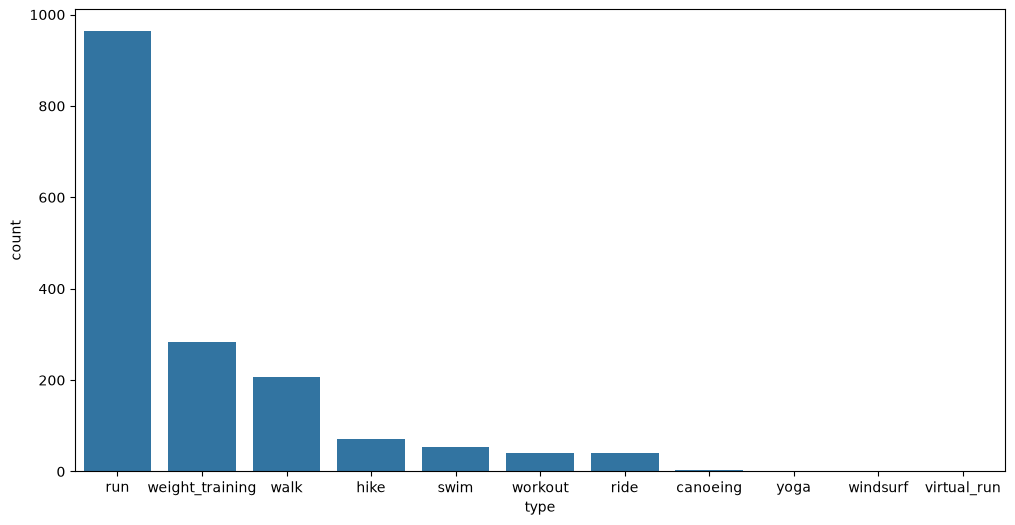

In [3]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=activities["type"].value_counts().reset_index(), x="type", y="count", ax=ax
)

In [4]:
act = activities[activities["type"] == "run"].sort_values(
    "distance_km", ascending=False
)
print(act.shape)
file_path = act[act["id"] == 11807872158].iloc[0]["file_name"]
act.head(5)

(963, 102)


,id,date,name,type,description,elapsed_time,distance_km,max_heart_rate,relative_effort,is_commute,...,is_recovery,with_pet,is_race,is_long_run,is_charity,with_child,downhill_distance,total_sets,total_reps,support
683,13026008640,"30 nov. 2024, 23:11:13",[🏃 🏃🏼‍♀️ Saintélyon 🌜🌞],run,Une saintélyon en binôme avec [strava://athlet...,43813.0,82.36,179.0,577.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,media/9564868f-742d-4b17-8c78-7fec7294c7bd.jpg...
908,10975302024,"16 mars 2024, 10:36:08",[🗼80k - Ecotrail de Paris 🎂],run,🎉Premier 80km pour mes 27ans 🎂 🎊\r\n\r\nPremie...,33706.0,81.87,187.0,1085.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,media/f0e27ecf-caec-4e13-9ba7-d9357e9db464.jpg...
842,11682866712,"15 juin 2024, 07:30:40",[ 🐚 100k Saint-Jacques ],run,J'ai pris ma revanche sur le Saint-Jacques by ...,41920.0,81.01,183.0,1012.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,media/9d9e4ea3-9dec-477f-a79e-568d549b0aa8.jpg...
193,17807912509,"21 mars 2026, 09:42:34",[🗼80k - Ecotrail de Paris 🎂],run,J'ai réussi à obtenir un dossard il y a une se...,38540.0,80.68,179.0,790.0,False,...,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,media/70e2f4f3-1a41-4374-a31f-33b248575d8b.jpg...
831,11807872158,"4 juil. 2024, 05:30:04",[ 🇪🇸 PDA - Val D'Aran byUTMB 🗻 ],run,Très content d'avoir pu m'aligner sur la ligne...,32759.0,51.39,188.0,868.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,media/f2d3536c-3f32-4fdd-af8a-9bb4f5abcf66.jpg...


In [5]:
from TrailPredictor import RunningActivities

segment_width = 500
race = RunningActivities.from_computed_file(file_path, segment_width)
race.data.head(4)

,segment,elapsed_time,pace,timestamp,distance,speed,heart_rate,altitude,position_lat,position_long
0,0,0 days 00:02:55,2.857143,2024-07-04 05:30:04+00:00,500.0,2.711760,140.508571,1253.914286,42.706982,0.901362
1,1,0 days 00:02:34,3.246753,2024-07-04 05:32:59+00:00,1000.0,3.133766,161.740260,1246.922078,42.706031,0.904272
2,2,0 days 00:03:09,2.645503,2024-07-04 05:35:33+00:00,1500.0,2.746698,173.486772,1266.470899,42.704577,0.909567
3,3,0 days 00:02:59,2.793296,2024-07-04 05:38:42+00:00,2000.0,2.863257,173.284916,1288.625698,42.701976,0.914271


In [6]:
race.plot.pace_by_segment().show()
race.plot.hr_overlay().show()
race.plot.track_map().show()
race.plot.altitude().show()
race.plot.speed().show()
race.plot.time_in_hr_zones()

In [7]:
from TrailPredictor.plot import plot_minetti_curve

plot_minetti_curve()

In [8]:
from TrailPredictor.dataset import Dataset

dataset = Dataset.load(min_distance=18, max_distance=100, segment_width=100)
plotter = dataset.plot

In [9]:
strava_to_file = {
    "[🏃 🏃🏼‍♀️ Saintélyon 🌜🌞]": "Saintelyon",
    "[🗼80k - Ecotrail de Paris 🎂]": "80k_Ecotrail_de_Paris",
    # "[ 🐚 100k Saint-Jacques ]": "100k_Saint_Jacques",
    # "[ 🇪🇸 PDA - Val D'Aran byUTMB 🗻 ]": "PDA_Val_D_Aran_byUTMB",
    # "[🏃🏃‍♀️ Saint-Brieuc 2 Paimpol 🏖️]": "Saint_Brieuc_2_Paimpol",
    # "[🏃‍♂️ GRV-47K avec maxou la menace🔫": "GRV_47K_avec_maxou_la_menace",
    # "[🏃‍♂️ maratrail de Noël 🎄🎅]": "maratrail_de_Noel",
    # "[🏃‍♂️ trail - SaintExpress 🌃 🌨]": "trail_SaintExpress",
    # "[ 🐚 50k St-Jacques ]": "50k_St_Jacques",
    # "[🏃‍♂️trail - On déroule du km 🛣]": "trail_On_deroule_du_km",
    # "[ 🏃‍♂️ trail - maratrail pour le fun 🤷‍♂️]": "trail_maratrail_pour_le_fun",
    # "[ 🏃\u200d♂️ trail - maratrail de fin vacance 🏖️] ": "trail_maratrail_de_fin_vacance",
    # "[🇬🇷 Athens - maratrail d'adieu 🍒 🥧]": "Athens_maratrail_d_adieu",
    # "[ 🏃 Tour de la flemme - 15x🔥2x❄️]": "Tour_de_la_flemme_15x_2x",
    # "[🏃‍♂️course - UTCA• Ultra Trail des Côtes d'Armor 60k-relais ]": "course_UTCA_Ultra_Trail_des_Cotes_d_Armor_60k_relais",
    # "[🌉 Trail du Viaduc des Fauvettes 🧀]": "Trail_du_Viaduc_des_Fauvettes",
    # "[🏃🏃‍♀️Tour du Rocher de la Grand Paré 🏔️]": "Tour_du_Rocher_de_la_Grand_Paré",
    # "[🏃🏽 trail - sortie sous les arbres 🏞]": "trail_sortie_sous_les_arbres",
    "[ 🏴\U000e0067\U000e0062\U000e0073\U000e0063\U000e0074\U000e007f Mamores Stalker - Trail Race 🏴\U000e0067\U000e0062\U000e0073\U000e0063\U000e0074\U000e007f ]": "Mamores_Stalker_Trail_Race",
    # "[ 🐚 50k St-Jacques • J - 17 • Sortie en foret 🌲]": "50k_St_Jacques_J_17_Sortie_en_foret",
    # "[🏃🏼🏃🏼‍♀️ Gros Crail - ]": "Gros_Crail",
    # "[🏃 🏃🏼‍♀️ Sortir trail du week-end 🐄]": "Sortir_trail_du_week_end",
    # "[ 🏃 Trio Trail en Chevreuse 🏗️]": "Trio_Trail_en_Chevreuse",
    # "[🏃‍♂️UTCA-30K J - 8 • course nocturne • Trifouillette blanche 🌃 ]": "UTCA_30K_J_8_course_nocturne_Trifouillette_blanche",
    # "[🏃🏃🏼‍♀️Trail du dimanche 🌳]": "Trail_du_dimanche",
    # "[🏃‍♂️ maratrail de Noël 🎄🎅]": "maratrail_de_Noel",
}

dataset._data = dataset.data[dataset.data["name"].isin(strava_to_file.keys())]
print(len(strava_to_file), len(dataset.data["name"].unique()))
set(strava_to_file.keys()) - set(dataset.data["name"].unique())

3 3


set()

In [10]:
[name for name in dataset._data["name"].unique() if "UTCA" in name]

[]

In [11]:
# drop.pos + drop.pos.done + drop.pos.total +
#               drop.neg.done +
#               drop.pos.back.3k+
#               drop.neg.back.1k

from TrailPredictor.dataset import META_COLUMNS


dataset.features = [
    "altitude_drop_pos",
    "altitude_drop_neg_done",
    "altitude_drop_pos_done",
    "altitude_drop_pos_total",
    "altitude_drop_pos_back_3000",
    "altitude_drop_neg_back_1000",
    # "running_cost",
    # "walking_cost",
    # "slope",
]

In [12]:
# plotter.merge_figure(plotter.target_histogram, title="Histogram of target ")
# plotter.merge_figure(
#     plotter.target_vs_feat, title="Target vs Altitude Drop", features="altitude_drop"
# ).show()
# plotter.merge_figure(
#     plotter.target_vs_feat,
#     title="Target vs Altitude Drop (Positive)",
#     features="altitude_drop_pos",
# )

In [13]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, r2_score
from TrailPredictor.modeling import make_models

dataset.change_target("speed")
N_SPLITS = min(5, dataset.data["activity_id"].nunique())
RANDOM_STATE = 42
finite_rows = np.isfinite(dataset.target.to_numpy())
dataset._data = dataset._data.loc[finite_rows].reset_index(drop=True)
y = dataset.target
X = dataset.predictors
groups = dataset.data["activity_id"]

models = make_models()
pred = cross_val_predict(models["linear"], X, y, groups=groups)
dataset.prediction = pred

results = pd.concat(
    [
        dataset.true_total_time,
        dataset.predict_total_time(),
        # dataset.error_total_time(),
    ],
    axis=1,
)

# absolute error in minutes
results["error_total_time"] = np.abs(
    results["predict_total_time"] - results["true_total_time"]
)
results

/home/caill/project/strava/.venv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


,true_total_time,predict_total_time,error_total_time
activity_id,,,
0,0 days 12:10:13,0 days 12:27:41.803242140,0 days 00:17:28.803242140
1,0 days 09:21:47,0 days 08:50:42.364141281,0 days 00:31:04.635858719
3,0 days 10:42:20,0 days 08:31:39.197936663,0 days 02:10:40.802063337
34,0 days 03:57:34,0 days 03:38:13.616730343,0 days 00:19:20.383269657


In [14]:
models["linear"].fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['altitude_drop_pos','altitude_drop_neg_done','altitude_drop_pos_done', 'altitude_drop_pos_total','altitude_drop_pos_back_3000', 'altitude_drop_neg_back_1000']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [19]:
dataset.data

,segment,elapsed_time,pace,timestamp,distance,speed,heart_rate,altitude,position_lat,position_long,...,distance_back_3000,distance_front_3000,distance_back_5000,distance_front_5000,distance_back_10000,distance_front_10000,slope,walking_cost,running_cost,speed_pred
0,0,0 days 00:00:46,2.173913,2024-11-30 23:11:13+00:00,100.0,1.883196,113.326087,483.043478,45.450644,4.398385,...,0.0,33989900.0,0.0,33989900.0,0.0,33989900.0,0.000000,1.000000,1.000000,3.480546
1,1,0 days 00:00:38,2.631579,2024-11-30 23:11:59+00:00,200.0,2.292684,151.289474,484.868421,45.451534,4.398473,...,100.0,33989700.0,100.0,33989700.0,100.0,33989700.0,0.009125,1.073243,1.050487,3.324477
2,2,0 days 00:00:39,2.564103,2024-11-30 23:12:37+00:00,300.0,2.569103,168.230769,486.871795,45.452436,4.398672,...,300.0,33989400.0,300.0,33989400.0,300.0,33989400.0,0.006678,1.053271,1.036742,3.307292
3,3,0 days 00:00:35,2.857143,2024-11-30 23:13:16+00:00,400.0,2.543886,159.828571,488.485714,45.453286,4.398923,...,600.0,33989000.0,600.0,33989000.0,600.0,33989000.0,0.004035,1.031969,1.022064,3.338485
4,4,0 days 00:00:36,2.777778,2024-11-30 23:13:51+00:00,500.0,2.783556,151.277778,489.638889,45.454025,4.399617,...,1000.0,33988500.0,1000.0,33988500.0,1000.0,33988500.0,0.002306,1.018192,1.012561,3.376186
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14986,261,0 days 00:00:29,3.448276,2023-09-17 11:40:12+00:00,26200.0,3.512828,188.724138,0.034483,56.713060,-4.957666,...,3419100.0,105800.0,3419100.0,105800.0,3419100.0,105800.0,-0.000037,0.999711,0.999800,2.556441
14987,262,0 days 00:00:30,3.333333,2023-09-17 11:40:41+00:00,26300.0,3.463067,189.166667,0.000000,56.713578,-4.959012,...,3445300.0,79500.0,3445300.0,79500.0,3445300.0,79500.0,-0.000001,0.999990,0.999993,2.559308
14988,263,0 days 00:00:28,3.571429,2023-09-17 11:41:11+00:00,26400.0,3.362607,188.750000,0.000000,56.714196,-4.960174,...,3471600.0,53100.0,3471600.0,53100.0,3471600.0,53100.0,0.000000,1.000000,1.000000,2.559413
14989,264,0 days 00:00:23,4.347826,2023-09-17 11:41:39+00:00,26500.0,3.571478,190.478261,-0.217391,56.714344,-4.961383,...,3498000.0,26600.0,3498000.0,26600.0,3498000.0,26600.0,-0.000008,0.999936,0.999956,2.558913


In [20]:
dataset.predictors

,altitude_drop_pos,altitude_drop_neg_done,altitude_drop_pos_done,altitude_drop_pos_total,altitude_drop_pos_back_3000,altitude_drop_neg_back_1000
0,0.000000,0.000000,0.000000,2371.757135,0.000000,0.000000
1,1.824943,0.000000,1.824943,2371.757135,0.000000,0.000000
2,2.003374,0.000000,3.828317,2371.757135,1.824943,0.000000
3,1.613919,0.000000,5.442236,2371.757135,3.828317,0.000000
4,1.153175,0.000000,6.595411,2371.757135,5.442236,0.000000
...,...,...,...,...,...,...
14986,0.000000,-1143.387573,1164.774997,1164.838542,1164.774997,-1142.422056
14987,0.000000,-1143.422056,1164.774997,1164.838542,1164.774997,-1143.387573
14988,0.000000,-1143.422056,1164.774997,1164.838542,1164.774997,-1143.422056
14989,0.000000,-1143.639447,1164.774997,1164.838542,1164.774997,-1143.422056


In [16]:
for activity_id in dataset.data["activity_id"].unique():
    if (
        not "Mamores"
        in dataset._data[dataset._data["activity_id"] == activity_id]
        .loc[:, "name"]
        .values[0]
    ):
        continue

    race = dataset.get_activities(activity_id)
    race.plot.speed().show()

In [17]:
dataset.true_total_time.mean()

Timedelta('0 days 09:02:58.500000')

In [18]:
models = make_models()
dataset.change_target("pace")
finite_rows = np.isfinite(dataset.target.to_numpy())
dataset._data = dataset._data.loc[finite_rows].reset_index(drop=True)
y = dataset.target
X = dataset.predictors
groups = dataset.data["activity_id"]
N_SPLITS = min(5, dataset.data["activity_id"].nunique())
cv = GroupKFold(n_splits=N_SPLITS)
rows = []
for name, pipe in models.items():
    pred = cross_val_predict(pipe, X, y, groups=groups, cv=cv)
    dataset.prediction = pd.Series(pred, index=y.index, name="pace_pred")
    err = dataset.true_total_time / dataset.predict_total_time() - 1
    rows.append(
        {
            "modèle": name,
            "R² vitesse": r2_score(y, pred),
            "MAE": mean_absolute_error(y, pred),
            "Predicted total time (%)": dataset.predict_total_time().mean(),
            "Error total time (%)": err.abs().mean(),
        }
    )

metrics = pd.DataFrame(rows).set_index("modèle")
display_fn = globals().get("display", print)
display_fn(metrics.round(3))

best = metrics["MAE"].idxmin()
print(f"Modèle retenu : {best}")

NameError: name 'GroupKFold' is not defined

In [ ]:
dataset._data.groupby("activity_id")["elapsed_time"].sum()

activity_id
0    0 days 12:10:13
1    0 days 09:21:47
2    0 days 11:38:40
3    0 days 10:42:20
4    0 days 09:05:59
6    0 days 06:38:38
7    0 days 05:52:52
8    0 days 05:55:50
9    0 days 05:08:39
10   0 days 05:50:58
15   0 days 04:06:47
16   0 days 04:33:35
17   0 days 04:30:16
18   0 days 05:38:33
24   0 days 03:09:31
28   0 days 03:15:42
30   0 days 06:46:31
31   0 days 03:03:20
34   0 days 03:57:34
47   0 days 02:08:14
58   0 days 02:26:09
66   0 days 02:35:50
68   0 days 02:18:12
85   0 days 02:00:04
Name: elapsed_time, dtype: timedelta64[us]

In [ ]:
dataset.change_target("speed")
dataset.prediction = dataset.target

predicted_speed = dataset.prediction.astype(float)
print(predicted_speed)
activity_id = dataset._data["activity_id"]
x = (
    pd.DataFrame(
        {"activity_id": activity_id, "speed": predicted_speed, "target": dataset.target}
    )
    .assign(
        time=pd.to_timedelta(
            dataset._segment_width / predicted_speed, unit="s"
        )
    )
)
x["pace"] = 1000 / (60 * x["speed"])
x


0         7.826087
1         9.473684
2         9.230769
3        10.285714
4        10.000000
           ...    
26016    10.588235
26017    11.250000
26018    12.000000
26019     9.473684
26020    13.846154
Name: speed_pred, Length: 10243, dtype: float64


,activity_id,speed,target,time,pace
0,0,7.826087,2.173913,0 days 00:00:46.000000000,21.739130
1,0,9.473684,2.631579,0 days 00:00:38.000000001,26.315789
2,0,9.230769,2.564103,0 days 00:00:38.999999998,25.641026
3,0,10.285714,2.857143,0 days 00:00:34.999999999,28.571429
4,0,10.000000,2.777778,0 days 00:00:36.000000000,27.777778
...,...,...,...,...,...
26016,85,10.588235,2.941176,0 days 00:00:33.999999998,29.411765
26017,85,11.250000,3.125,0 days 00:00:32.000000000,31.250000
26018,85,12.000000,3.333333,0 days 00:00:29.999999998,33.333333
26019,85,9.473684,2.631579,0 days 00:00:38.000000001,26.315789
